In [12]:
import pandas as pd

pd.set_option("display.max_columns", None)   # show all columns

device_exposure = pd.read_csv("data/Device_exposure_per_visit.csv")
measurements = pd.read_csv("data/Measurements_per_visit.csv")

In [13]:
print(device_exposure.head())

   visit_occurrence_id  device_exposure_id device_exposure_start_datetime device_exposure_end_datetime  duur_uren
0                    5          1437661717        2013-01-01 00:48:00 UTC      2013-01-02 20:22:00 UTC         43
1                   11          1437661769        2006-01-01 01:04:00 UTC      2006-01-02 12:54:00 UTC         35
2                   15          1437661808        2013-01-01 01:53:00 UTC      2013-01-03 18:32:00 UTC         64
3                   15          1437661810        2013-01-03 18:38:00 UTC      2013-01-10 20:40:00 UTC        170
4                   18          1437661830        2013-01-01 00:03:00 UTC      2013-01-01 07:33:00 UTC          7


In [14]:
print(measurements.head())

   visit_occurrence_id  dag_nr       datum  uur                uur_start  n_metingen  m_3024882  m_3025408  m_3014080  m_40762499  m_3022875  m_21490855  m_3016078  m_42527086  m_3000461  m_42527137  m_3007469  \
0                 4587      29  2006-01-29   12  2006-01-29 12:00:00 UTC          21      40.00      40.00        NaN         NaN       6.00        6.00      15.00        8.00       8.00         NaN        NaN   
1                 4587      29  2006-01-29   13  2006-01-29 13:00:00 UTC          23      40.00      40.00        NaN       97.00       6.00        6.00      15.00        9.00       8.00         NaN        NaN   
2                 4587      29  2006-01-29   14  2006-01-29 14:00:00 UTC          31      40.00      40.00        NaN         NaN       6.00        6.00      14.00        9.00       8.00         NaN        NaN   
3                 4587      29  2006-01-29   15  2006-01-29 15:00:00 UTC          23      40.00      40.00        NaN       97.50       6.00        

Numeric features: 44 | Categorical features: 6
Measurements: (1190534, 56) | Device exposure: (6768, 5)
Visits in measurements: 5260
Visits in device_exposure: 5260
Duplicate (visit, hour) rows: 0

Hours per visit:
 count   5,260.00
mean      226.34
std       286.65
min         3.00
25%        49.00
50%       120.00
75%       285.00
max     3,184.00
dtype: float64

Device duration (hours):
 count   6,768.00
mean      126.86
std       165.55
min         4.00
25%        21.00
50%        65.00
75%       168.00
max     1,825.00
Name: duur_uren, dtype: float64

Device rows per visit:
 count   5,260.00
mean        1.29
std         0.69
min         1.00
25%         1.00
50%         1.00
75%         1.00
max         7.00
dtype: float64

Gap between consecutive rows (hours):
 uur_start
1.00     1074416
2.00       81510
3.00        6507
4.00        4335
5.00        3023
6.00        1729
24.00       1629
7.00        1164
8.00        1115
9.00         926
Name: count, dtype: int64

               

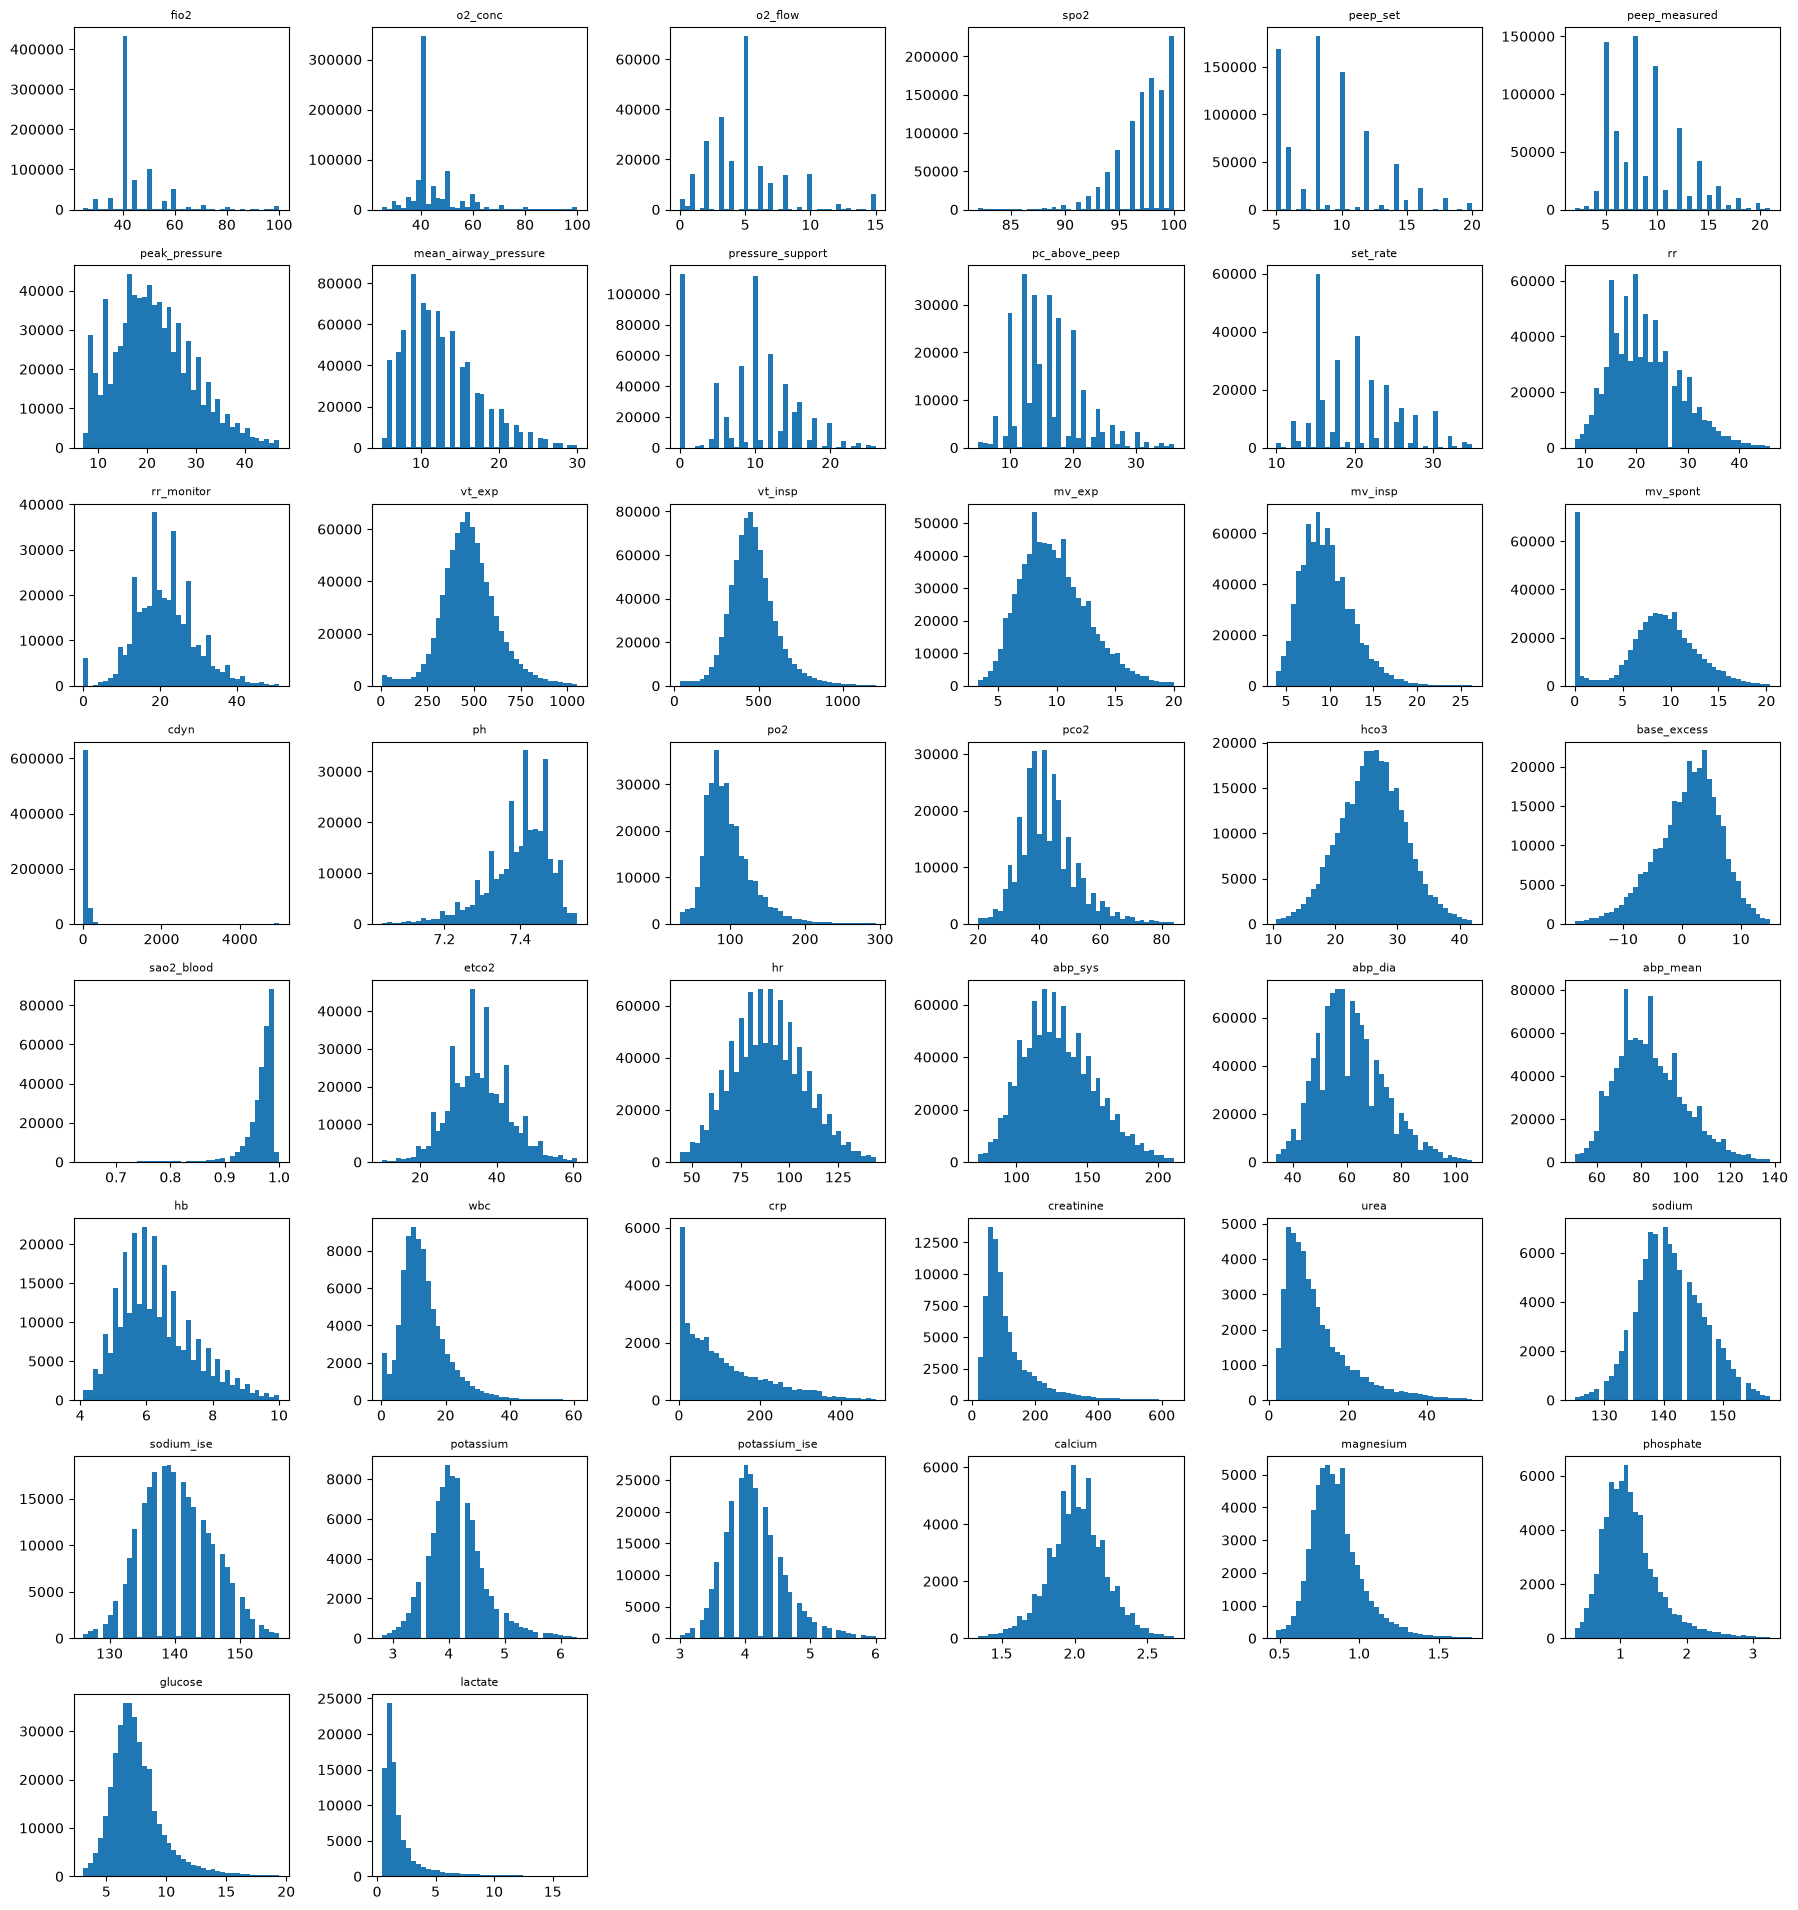

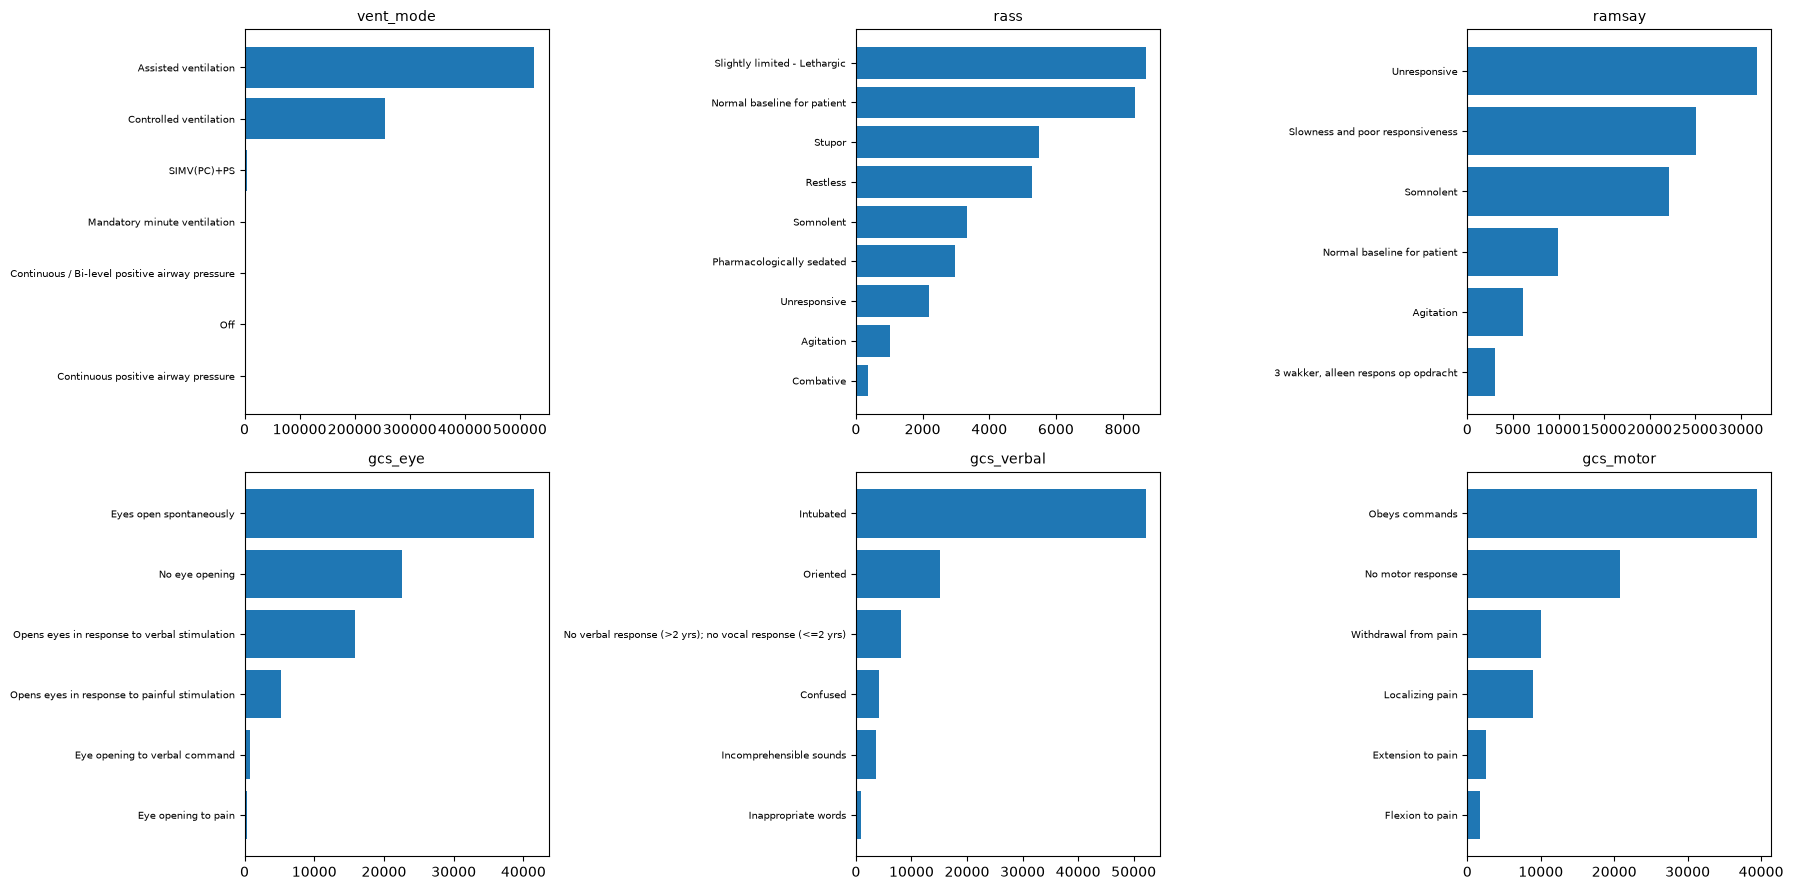

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

# 2. Readable feature names
names = {
    3024882: "fio2", 3025408: "o2_conc", 3014080: "o2_flow", 40762499: "spo2",
    3022875: "peep_set", 21490855: "peep_measured", 3016078: "peak_pressure",
    42527086: "mean_airway_pressure", 3000461: "pressure_support", 42527137: "pc_above_peep",
    3007469: "set_rate", 3007646: "rr", 3024171: "rr_monitor", 3015016: "vt_exp",
    3016166: "vt_insp", 42527120: "mv_exp", 42527121: "mv_insp", 4108000: "mv_spont",
    3004921: "vent_mode", 21490582: "cdyn", 3010421: "ph", 3027315: "po2",
    3013290: "pco2", 3006576: "hco3", 3012501: "base_excess", 42869608: "sao2_blood",
    3035357: "etco2", 21490872: "hr", 21490853: "abp_sys", 21490851: "abp_dia",
    21490852: "abp_mean", 40762351: "hb", 3010813: "wbc", 3020460: "crp",
    3020564: "creatinine", 43534077: "urea", 3019550: "sodium", 3000285: "sodium_ise",
    3023103: "potassium", 3005456: "potassium_ise", 3015377: "calcium",
    3012095: "magnesium", 3003458: "phosphate", 3020491: "glucose", 3047181: "lactate",
    36684829: "rass", 4105091: "ramsay", 3016335: "gcs_eye", 3009094: "gcs_verbal",
    3008223: "gcs_motor",
}
categorical_ids = [3004921, 36684829, 4105091, 3016335, 3009094, 3008223]
numeric_ids = [k for k in names if k not in categorical_ids]

# drop the old (always empty) numeric columns of the categorical items, if still present
measurements = measurements.drop(
    columns=[f"m_{k}" for k in categorical_ids if f"m_{k}" in measurements.columns]
)

rename_map = {f"m_{k}": names[k] for k in numeric_ids}
rename_map.update({f"c_{k}": names[k] for k in categorical_ids})
measurements = measurements.rename(columns=rename_map)

numeric_features = [names[k] for k in numeric_ids if names[k] in measurements.columns]
categorical_features = [names[k] for k in categorical_ids if names[k] in measurements.columns]
print("Numeric features:", len(numeric_features), "| Categorical features:", len(categorical_features))

# clean up the text of the categorical columns
for c in categorical_features:
    measurements[c] = measurements[c].astype("string").str.strip()

# 3. Types, sorting, structure checks
measurements["uur_start"] = pd.to_datetime(measurements["uur_start"])
measurements = measurements.sort_values(["visit_occurrence_id", "uur_start"]).reset_index(drop=True)
for col in ["device_exposure_start_datetime", "device_exposure_end_datetime"]:
    device_exposure[col] = pd.to_datetime(device_exposure[col])

print("Measurements:", measurements.shape, "| Device exposure:", device_exposure.shape)
print("Visits in measurements:", measurements["visit_occurrence_id"].nunique())
print("Visits in device_exposure:", device_exposure["visit_occurrence_id"].nunique())
print("Duplicate (visit, hour) rows:",
      measurements.duplicated(["visit_occurrence_id", "uur_start"]).sum())

print("\nHours per visit:\n", measurements.groupby("visit_occurrence_id").size().describe())
print("\nDevice duration (hours):\n", device_exposure["duur_uren"].describe())
print("\nDevice rows per visit:\n", device_exposure.groupby("visit_occurrence_id").size().describe())

gap_h = measurements.groupby("visit_occurrence_id")["uur_start"].diff().dt.total_seconds() / 3600
print("\nGap between consecutive rows (hours):\n", gap_h.value_counts().head(10))

# 4a. Numeric features: min, max, percentiles, outliers
num = measurements[numeric_features].apply(pd.to_numeric, errors="coerce")

q1, q3 = num.quantile(0.25), num.quantile(0.75)
iqr = q3 - q1
n_out = (num.lt(q1 - 1.5 * iqr) | num.gt(q3 + 1.5 * iqr)).sum()

summary = pd.DataFrame({
    "n": num.count(),
    "pct_missing": num.isna().mean() * 100,
    "min": num.min(), "p1": num.quantile(0.01), "median": num.median(),
    "mean": num.mean(), "p99": num.quantile(0.99), "max": num.max(), "std": num.std(),
    "n_negative": num.lt(0).sum(), "n_zero": num.eq(0).sum(),
    "n_outliers_iqr": n_out, "pct_outliers_iqr": n_out / num.count() * 100,
})
print("\n", summary.sort_values("pct_missing"))
summary.to_csv("data/feature_summary.csv")

# 4b. Categorical features: missingness, unique values, value counts
cat_summary = pd.DataFrame({
    "n": [measurements[c].notna().sum() for c in categorical_features],
    "pct_missing": [measurements[c].isna().mean() * 100 for c in categorical_features],
    "n_unique": [measurements[c].nunique() for c in categorical_features],
    "top_value": [measurements[c].value_counts().index[0] if measurements[c].notna().any() else None
                  for c in categorical_features],
    "top_share_pct": [measurements[c].value_counts(normalize=True).iloc[0] * 100
                      if measurements[c].notna().any() else np.nan for c in categorical_features],
}, index=categorical_features)
print("\nCategorical summary:\n", cat_summary)
cat_summary.to_csv("data/categorical_summary.csv")

for c in categorical_features:
    print(f"\n--- {c} ---")
    print(measurements[c].value_counts(dropna=False).head(20))

# 5a. Histograms (numeric), without the 0.5% most extreme values on each side
cols = list(num.columns)
n_cols = 6
n_rows = int(np.ceil(len(cols) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(3 * n_cols, 2.4 * n_rows))
for ax, c in zip(axes.ravel(), cols):
    s = num[c].dropna()
    if len(s):
        lo, hi = s.quantile([0.005, 0.995])
        ax.hist(s[(s >= lo) & (s <= hi)], bins=40)
    ax.set_title(c, fontsize=8)
for ax in axes.ravel()[len(cols):]:
    ax.axis("off")
plt.tight_layout()
plt.savefig("data/histograms.png", dpi=120)
plt.show()

# 5b. Bar charts (categorical): the 12 most frequent values per feature
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, c in zip(axes.ravel(), categorical_features):
    vc = measurements[c].value_counts().head(12)
    ax.barh(vc.index.astype(str)[::-1], vc.values[::-1])
    ax.set_title(c, fontsize=10)
    ax.tick_params(axis="y", labelsize=7)
for ax in axes.ravel()[len(categorical_features):]:
    ax.axis("off")
plt.tight_layout()
plt.savefig("data/categorical_counts.png", dpi=120)
plt.show()

In [ ]:
# first data cleaning (need to check)

import numpy as np
import pandas as pd

KPA_TO_MMHG = 7.50062

ranges = {
    # vitals
    "hr": (20, 250), "abp_sys": (20, 300), "abp_dia": (10, 200), "abp_mean": (20, 220),
    "spo2": (40, 100),
    # oxygen and ventilator
    "fio2": (20, 100), "o2_conc": (20, 100), "o2_flow": (0, 60),
    "peep_set": (0, 35), "peep_measured": (0, 35), "peak_pressure": (3, 100),
    "mean_airway_pressure": (1, 70), "pressure_support": (0, 40), "pc_above_peep": (0, 60),
    "set_rate": (0, 60), "rr": (1, 80), "rr_monitor": (1, 80),
    "vt_exp": (20, 2000), "vt_insp": (20, 2000), "mv_exp": (0.5, 40), "mv_insp": (0.5, 40),
    "mv_spont": (0, 40), "etco2": (5, 100),
    # blood gas
    "ph": (6.6, 7.9), "pco2": (10, 200), "po2": (20, 700), "hco3": (3, 60),
    "base_excess": (-30, 30), "sao2_blood": (0.3, 1.0),
    # labs
    "hb": (2, 15), "wbc": (0.1, 500), "crp": (0, 800), "creatinine": (10, 2000),
    "urea": (0.5, 80), "sodium": (100, 180), "sodium_ise": (100, 180),
    "potassium": (1.5, 10), "potassium_ise": (1.5, 10), "calcium": (0.5, 4),
    "magnesium": (0.1, 5), "phosphate": (0.1, 10), "glucose": (0.5, 60), "lactate": (0.1, 30),
}

clean = measurements.copy()

# ---------- 1. Unit fixes (before the range filter) ----------
# pco2 / po2: a subset is recorded in kPa; values this low are not plausible in mmHg
for col, thr in {"pco2": 10, "po2": 20}.items():
    kpa = clean[col].gt(0) & clean[col].lt(thr)
    clean.loc[kpa, col] = clean.loc[kpa, col] * KPA_TO_MMHG
    print(f"{col}: {int(kpa.sum())} values converted from kPa to mmHg")

# SaO2: mostly a fraction (median 0.98), some entries look like percentages
s = clean["sao2_blood"]
clean["sao2_blood"] = np.where(s > 1.5, s / 100, s)

# ---------- 2. Drop redundant / unreliable features ----------
# cdyn is artefact-prone in assisted ventilation and correlates 0.93 with vt / (peak - peep)
clean = clean.drop(columns=["cdyn"])

# ---------- 3. Range filter: implausible values -> NaN ----------
report = []
for col, (lo, hi) in ranges.items():
    valid = clean[col].notna()
    below = valid & (clean[col] < lo)
    above = valid & (clean[col] > hi)
    bad = below | above
    report.append({
        "feature": col,
        "n_valid_before": int(valid.sum()),
        "n_removed": int(bad.sum()),
        "n_below": int(below.sum()),
        "n_above": int(above.sum()),
        "pct_removed": round(bad.sum() / valid.sum() * 100, 3),
        "min_removed": clean.loc[bad, col].min() if bad.any() else np.nan,
        "max_removed": clean.loc[bad, col].max() if bad.any() else np.nan,
    })
    clean.loc[bad, col] = np.nan

report = pd.DataFrame(report).sort_values("pct_removed", ascending=False)
print(report.to_string())
report.to_csv("data/cleaning_report.csv", index=False)

# ---------- 4. Categorical features ----------
gcs_eye_map = {
    "Eyes open spontaneously": 4,
    "Opens eyes in response to verbal stimulation": 3, "Eye opening to verbal command": 3,
    "Opens eyes in response to painful stimulation": 2, "Eye opening to pain": 2,
    "No eye opening": 1,
}
gcs_motor_map = {
    "Obeys commands": 6, "Localizing pain": 5, "Withdrawal from pain": 4,
    "Flexion to pain": 3, "Extension to pain": 2, "No motor response": 1,
}
gcs_verbal_map = {
    "Oriented": 5, "Confused": 4, "Inappropriate words": 3, "Incomprehensible sounds": 2,
    "No verbal response (>2 yrs); no vocal response (<=2 yrs)": 1,
}

clean["gcs_eye_n"] = clean["gcs_eye"].map(gcs_eye_map)
clean["gcs_motor_n"] = clean["gcs_motor"].map(gcs_motor_map)
clean["gcs_verbal_n"] = clean["gcs_verbal"].map(gcs_verbal_map)       # "Intubated" stays NaN
clean["gcs_verbal_intubated"] = clean["gcs_verbal"].eq("Intubated")

vm = clean["vent_mode"]
clean["vent_mode_grp"] = (
    vm.map({"Assisted ventilation": "assisted", "Controlled ventilation": "controlled"})
      .fillna("other").where(vm.notna())
)
# rass and ramsay stay as text labels until the source values are checked

# unmapped labels would silently become NaN: report them
for col, mp in [("gcs_eye", gcs_eye_map), ("gcs_motor", gcs_motor_map)]:
    unmapped = set(clean[col].dropna().unique()) - set(mp)
    if unmapped:
        print(f"Unmapped labels in {col}:", unmapped)
unmapped = set(clean["gcs_verbal"].dropna().unique()) - set(gcs_verbal_map) - {"Intubated"}
if unmapped:
    print("Unmapped labels in gcs_verbal:", unmapped)

# ---------- 5. Checks and save ----------
assert len(clean) == len(measurements)
numeric_after = [c for c in ranges if c in clean.columns]
print("\nMin / median / max after cleaning:")
print(clean[numeric_after].agg(["min", "median", "max"]).T.to_string())

print("\nMissing per numeric feature after cleaning (%):")
print((clean[numeric_after].isna().mean() * 100).round(1).sort_values().to_string())

clean.to_csv("data/measurements_clean.csv", index=False)
print("\nSaved:", clean.shape)

pco2: 392 values converted from kPa to mmHg
po2: 413 values converted from kPa to mmHg
                 feature  n_valid_before  n_removed  n_below  n_above  pct_removed  min_removed  max_removed
16            rr_monitor          358313       6433     6208      225         1.79        -1.00     2,322.00
17                vt_exp          781562       6300     6224       76         0.81         0.00   161,298.00
18               vt_insp          781687       4623     2952     1671         0.59         0.00   679,771.00
22                 etco2          434465       1632     1611       21         0.38         0.00     3,490.00
20               mv_insp          781380       2421      102     2319         0.31         0.00     1,005.00
19                mv_exp          781549       1309     1253       56         0.17         0.00       733.00
28            sao2_blood          309270        250      244        6         0.08        -0.97         3.49
23                    ph          313024 

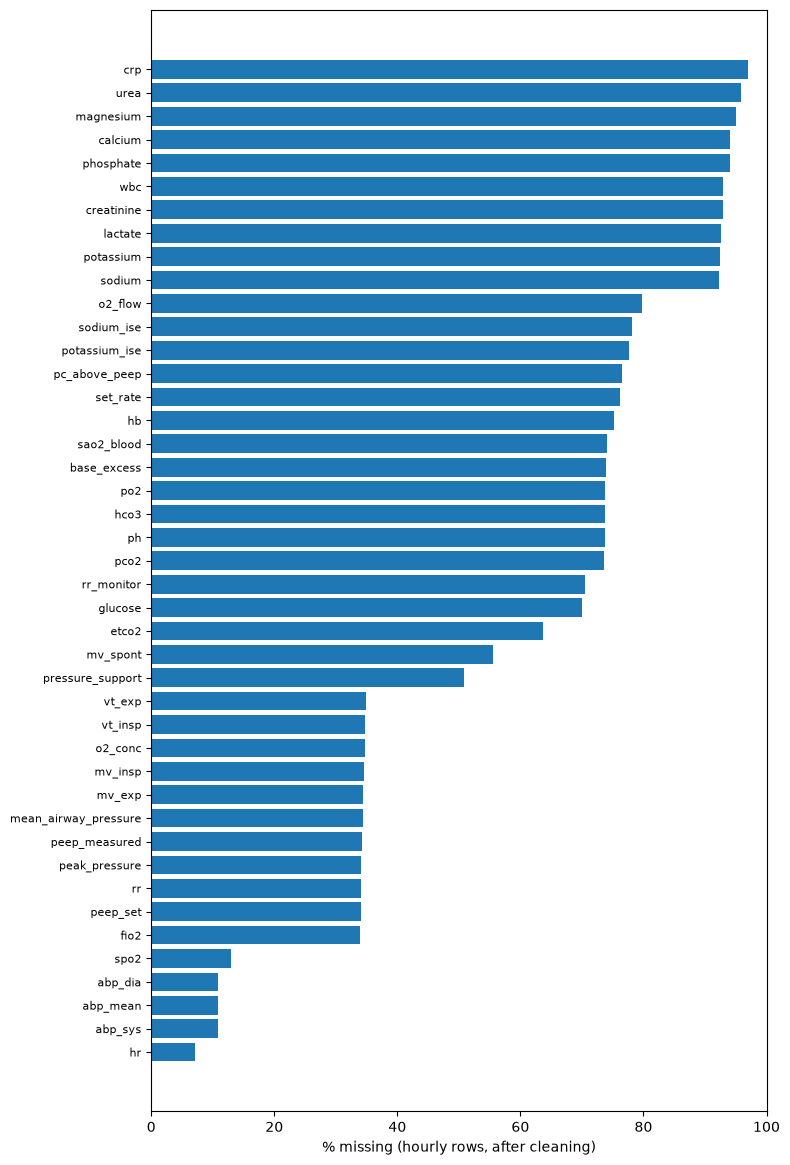

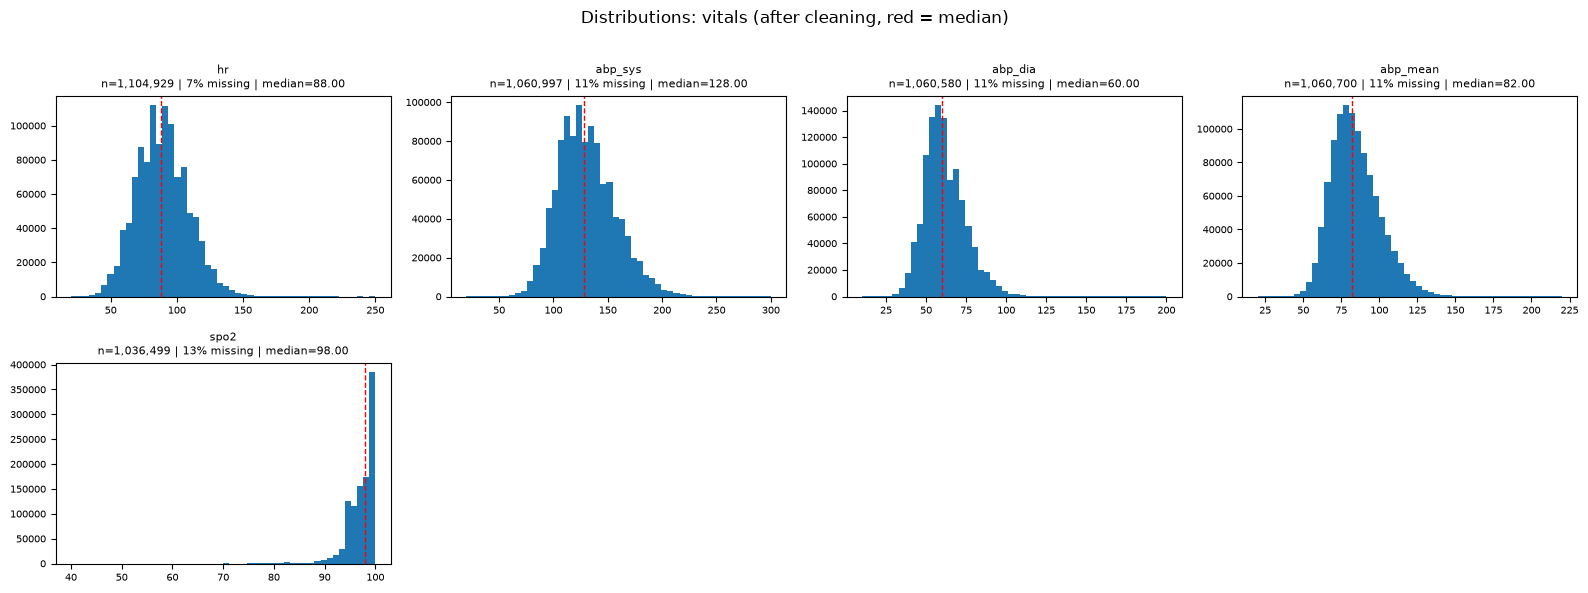

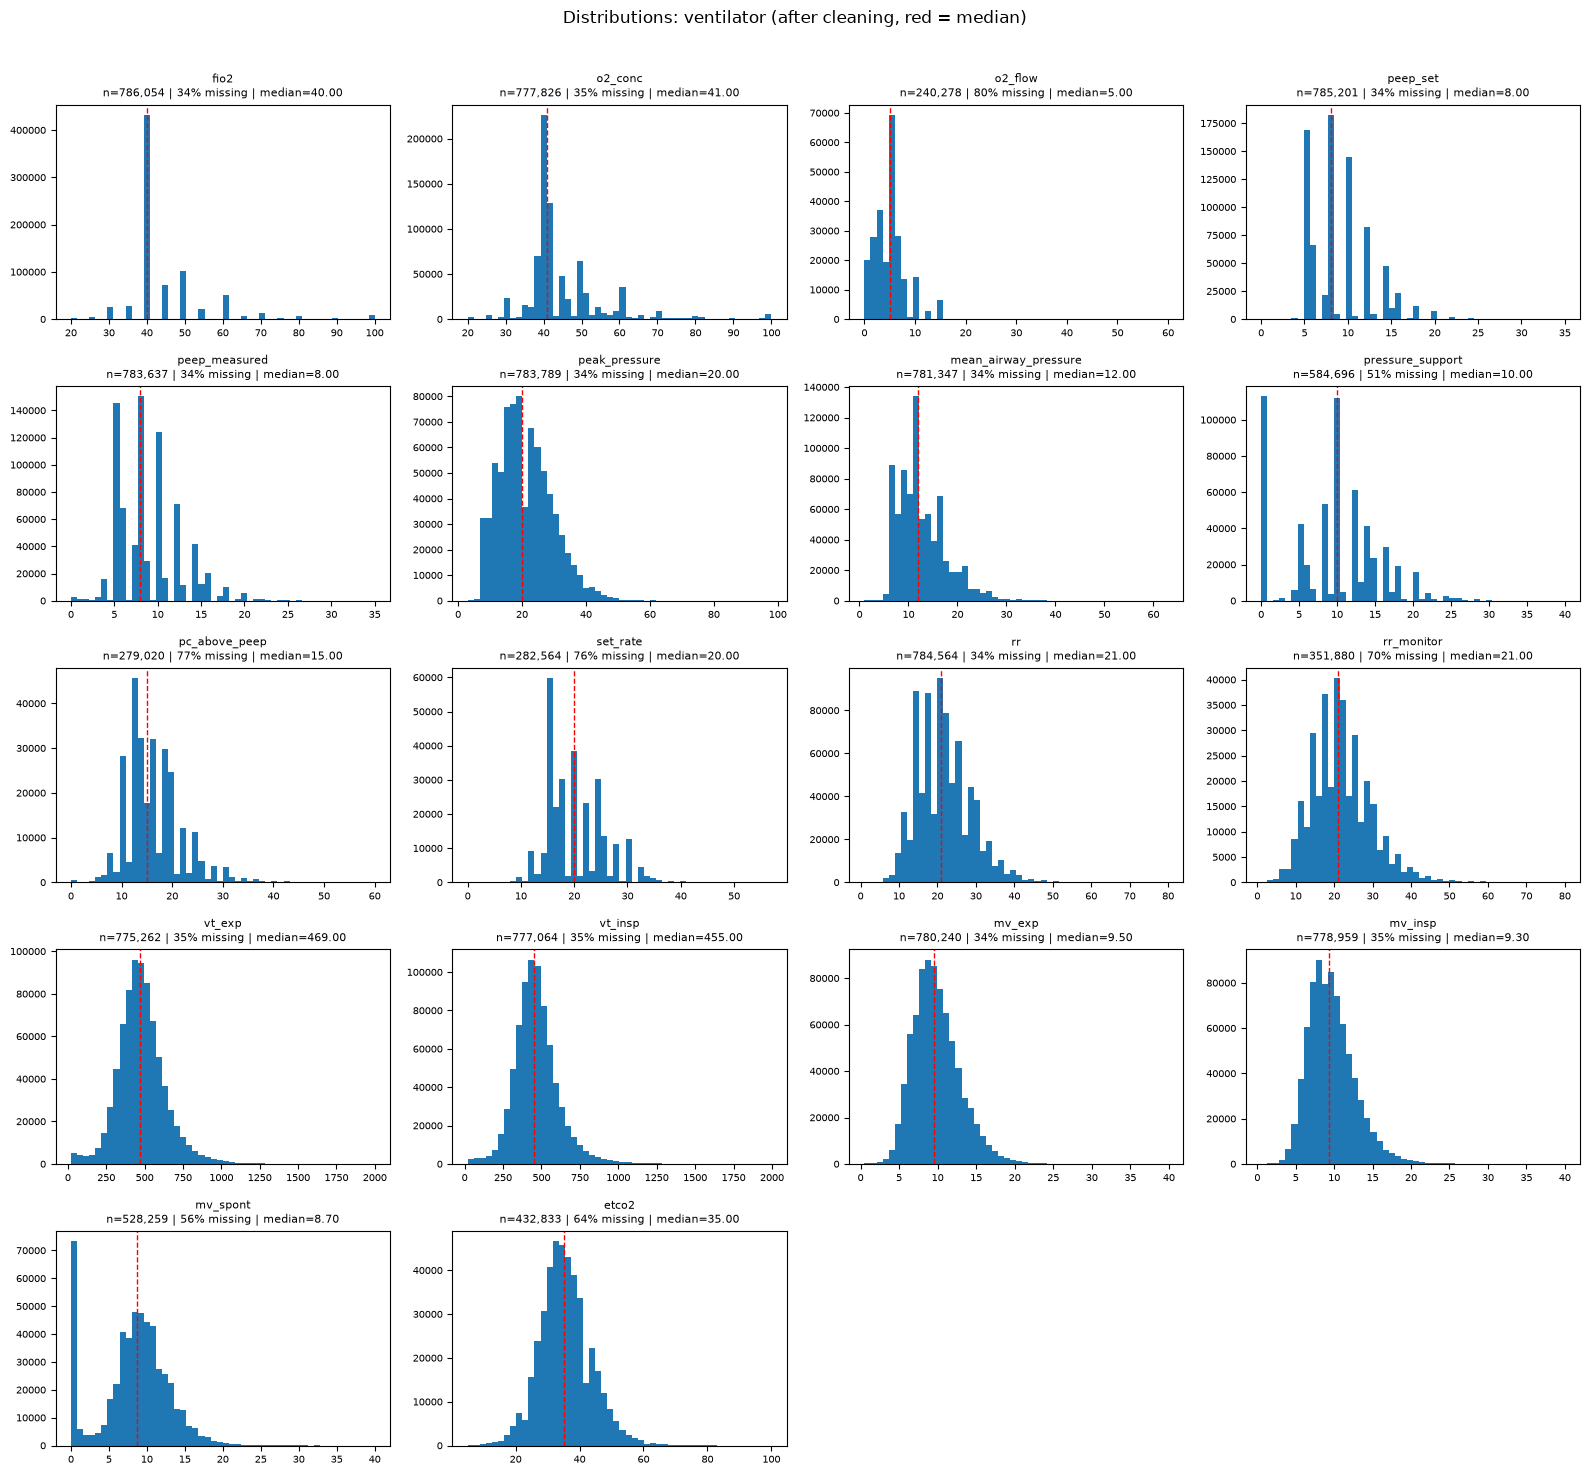

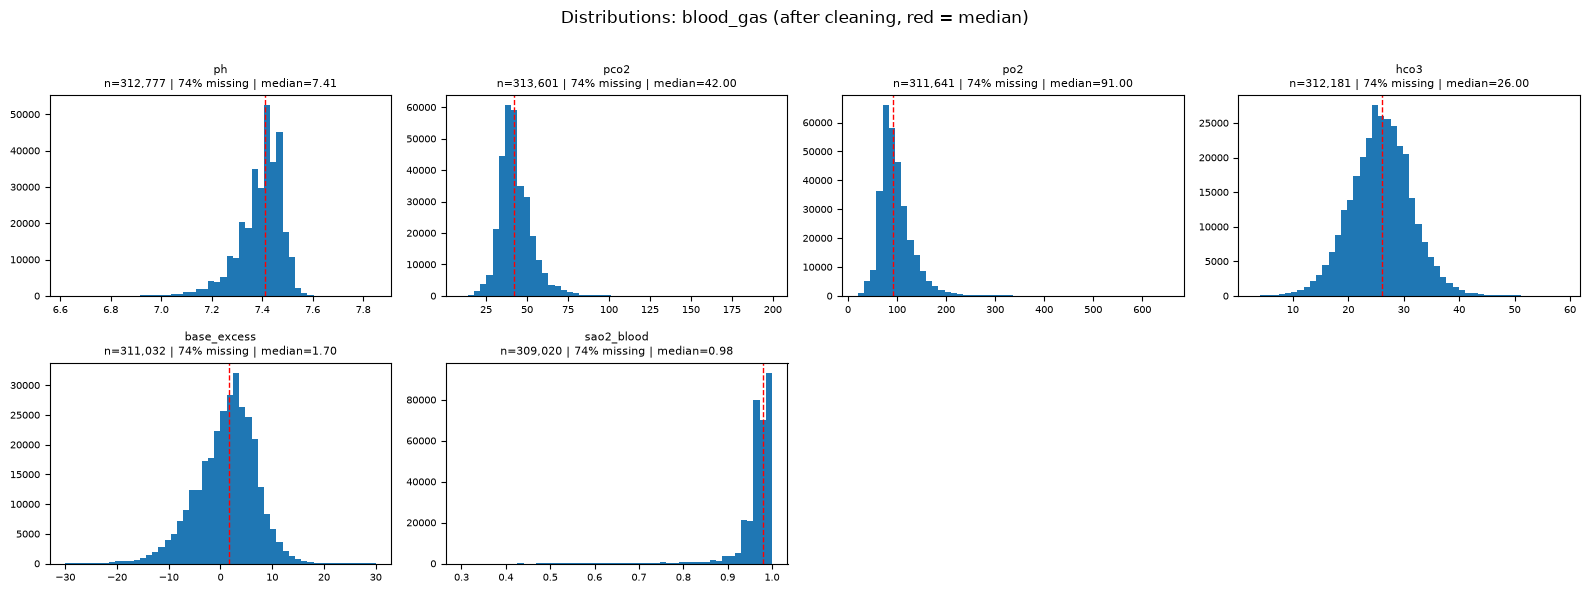

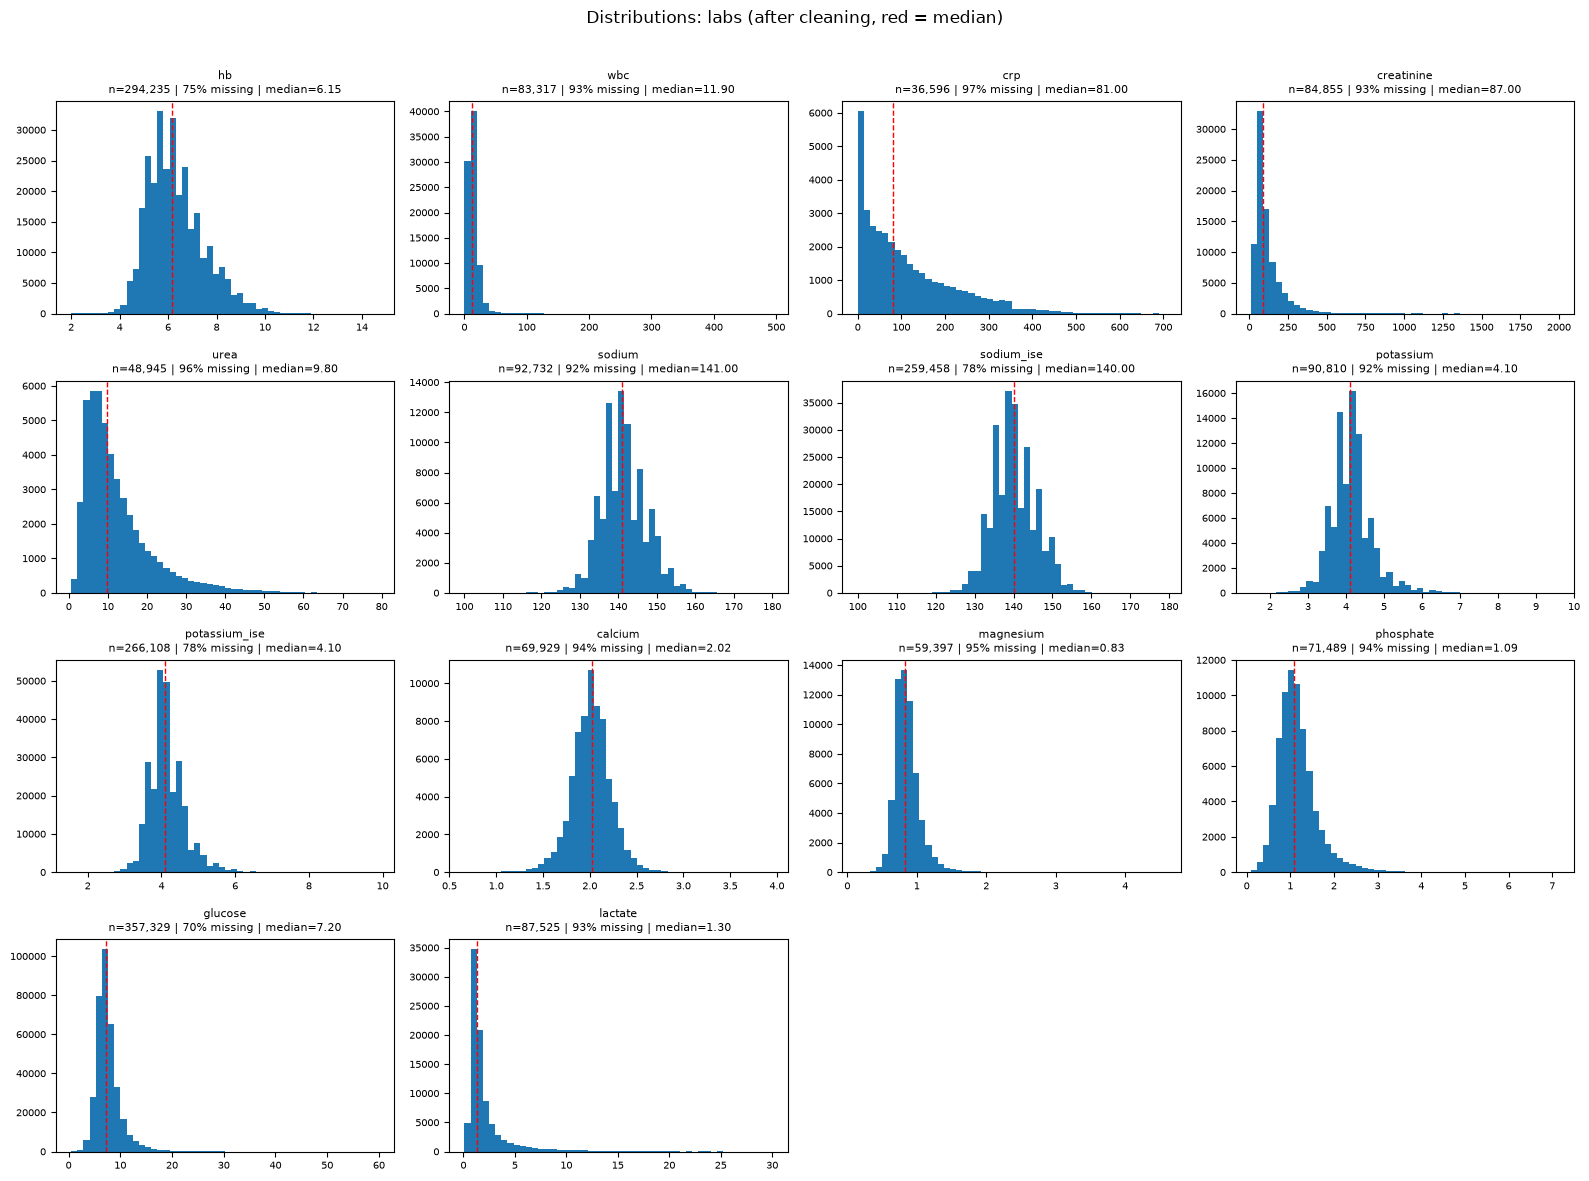

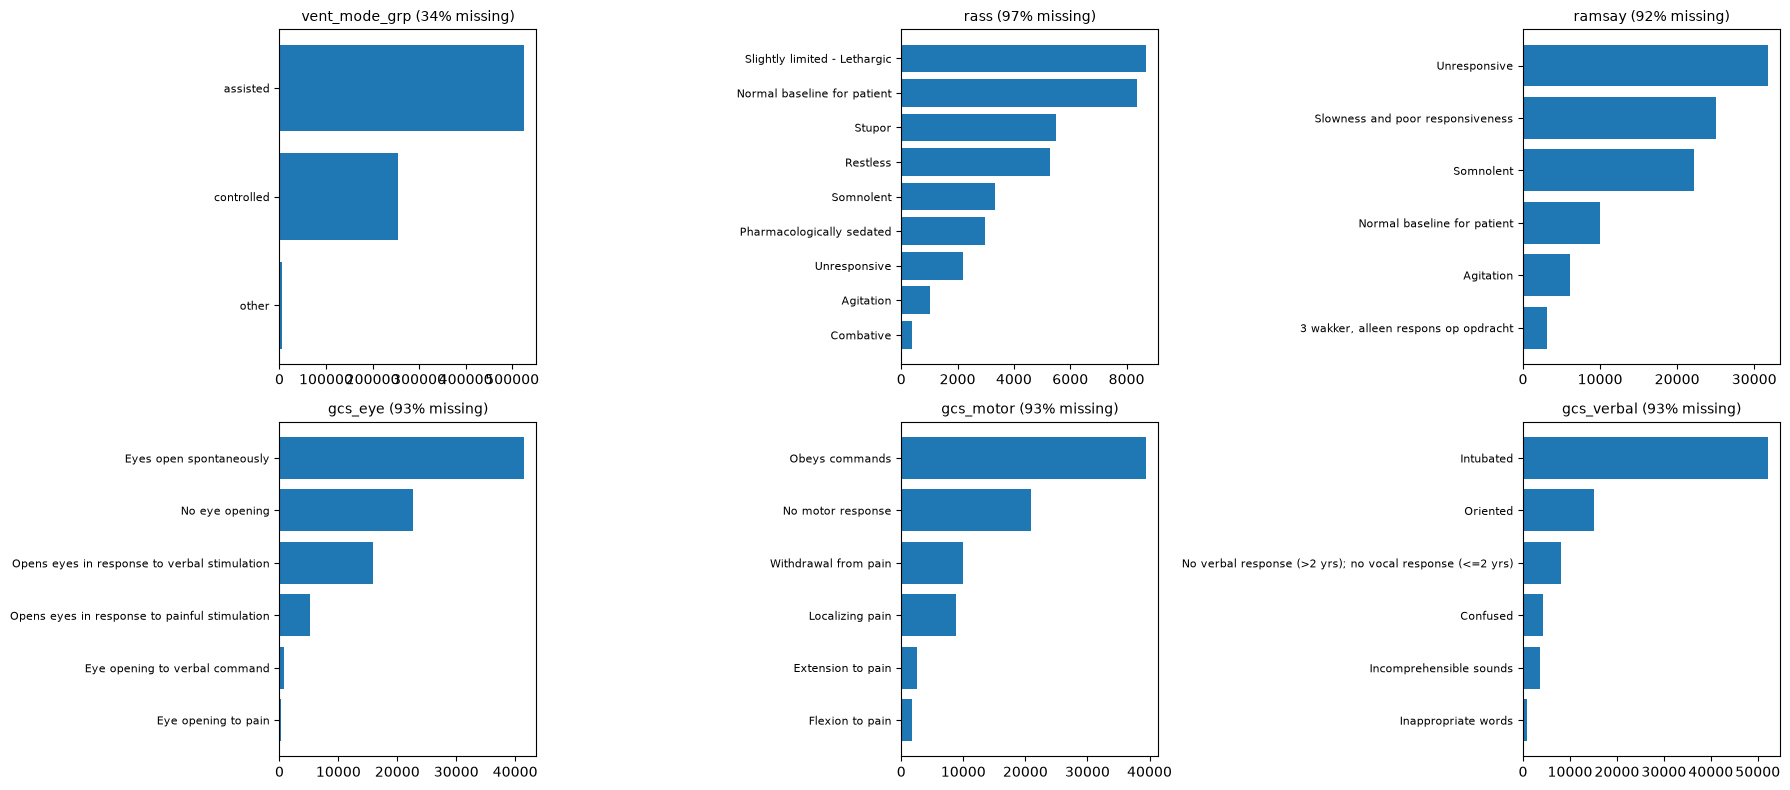

In [17]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

fig_dir = Path("data/figures")
fig_dir.mkdir(parents=True, exist_ok=True)

groups = {
    "vitals": ["hr", "abp_sys", "abp_dia", "abp_mean", "spo2"],
    "ventilator": ["fio2", "o2_conc", "o2_flow", "peep_set", "peep_measured", "peak_pressure",
                   "mean_airway_pressure", "pressure_support", "pc_above_peep", "set_rate",
                   "rr", "rr_monitor", "vt_exp", "vt_insp", "mv_exp", "mv_insp", "mv_spont", "etco2"],
    "blood_gas": ["ph", "pco2", "po2", "hco3", "base_excess", "sao2_blood"],
    "labs": ["hb", "wbc", "crp", "creatinine", "urea", "sodium", "sodium_ise",
             "potassium", "potassium_ise", "calcium", "magnesium", "phosphate", "glucose", "lactate"],
}
groups = {g: [c for c in cols if c in clean.columns] for g, cols in groups.items()}
all_numeric = [c for cols in groups.values() for c in cols]

# 1. Missingness per numeric feature (after cleaning)
miss = (clean[all_numeric].isna().mean() * 100).sort_values()
fig, ax = plt.subplots(figsize=(8, 0.25 * len(miss) + 1))
ax.barh(miss.index, miss.values)
ax.set_xlabel("% missing (hourly rows, after cleaning)")
ax.set_xlim(0, 100)
ax.tick_params(axis="y", labelsize=8)
plt.tight_layout()
plt.savefig(fig_dir / "missingness.png", dpi=130)
plt.show()

# 2. Histograms per feature group
def plot_group(name, cols, n_cols=4):
    n_rows = int(np.ceil(len(cols) / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 3 * n_rows))
    axes = np.atleast_1d(axes).ravel()
    for ax, c in zip(axes, cols):
        s = clean[c].dropna()
        if len(s) == 0:
            ax.set_title(f"{c}\n(no data)", fontsize=9)
            continue
        bins = int(min(50, max(10, s.nunique())))
        ax.hist(s, bins=bins)
        ax.axvline(s.median(), color="red", linestyle="--", linewidth=1)
        miss_pct = clean[c].isna().mean() * 100
        ax.set_title(f"{c}\nn={len(s):,} | {miss_pct:.0f}% missing | median={s.median():.2f}", fontsize=8)
        ax.tick_params(labelsize=7)
    for ax in axes[len(cols):]:
        ax.axis("off")
    fig.suptitle(f"Distributions: {name} (after cleaning, red = median)", fontsize=12)
    plt.tight_layout(rect=[0, 0, 1, 0.97])
    plt.savefig(fig_dir / f"hist_{name}_clean.png", dpi=130)
    plt.show()

for name, cols in groups.items():
    plot_group(name, cols)

# 3. Categorical features
cat_cols = [c for c in ["vent_mode_grp", "rass", "ramsay", "gcs_eye", "gcs_motor", "gcs_verbal"]
            if c in clean.columns]
fig, axes = plt.subplots(2, 3, figsize=(18, 8))
for ax, c in zip(axes.ravel(), cat_cols):
    vc = clean[c].value_counts().head(12)
    ax.barh(vc.index.astype(str)[::-1], vc.values[::-1])
    miss_pct = clean[c].isna().mean() * 100
    ax.set_title(f"{c} ({miss_pct:.0f}% missing)", fontsize=10)
    ax.tick_params(axis="y", labelsize=8)
for ax in axes.ravel()[len(cat_cols):]:
    ax.axis("off")
plt.tight_layout()
plt.savefig(fig_dir / "categorical_counts_clean.png", dpi=130)
plt.show()